#### MPAS Vertical interpolation
1) single level interpolation test
- Read MPAS cells
- Read MPAS data 
- interpolating the data from the model's vertical grid to a user-specified vertical grid using  np.interp for vertical interpolation assumes a log-linear relationship.
- Plotting 

2) Interpolating the data from the model's vertical grid to user-specified  pressure levels

##### Imports and vertical-interpolation helper functions


In [1]:
%matplotlib inline
 
import numpy as np
import xarray as xr
from scipy.interpolate import griddata

import matplotlib.collections as mplcollections
import matplotlib.patches as patches
import matplotlib.path as path
import matplotlib.tri as tri
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import cartopy.feature as cfeature
import cartopy.crs as ccrs
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [2]:
def vertical_interpolate_mpas(vcoord_2d, vinterp_2d, plev_1d):
    '''
    A function to interpolate MPAS grid data  to
    specified millibar. Assumes a log-linear relationship.
    input:
        vcoord_2d  : 2D vertical level values (e.g., pressure )
        vinterp_2d : 2D array of the variable to be interpolated to all pressure levels
        plev_1d    : 1D array containing veritcal levels to interpolate to
    return:
        interp_2d : 2D array that contains the interpolated variable on the interp_levels
    '''
    interp_2d = np.empty((len(plev_1d), vinterp_2d.shape[0]))
    
    for nc in range(vinterp_2d.shape[0]):
       interp_2d[:,nc] = vertical_interpolate(vcoord_2d[nc].values, vinterp_2d[nc].values, plev_1d)    
    
    return interp_2d

# from https://github.com/Unidata/python-training/blob/master/pages/gallery/Observational_Data_Cross_Section.ipynb
# The vertical interpolation assumes a log-linear relationship.
def vertical_interpolate(vcoord_data, interp_var, interp_levels):
    """A function to interpolate sounding data from each station to
    every millibar. Assumes a log-linear relationship.

    Input
    -----
    vcoord_data : A 1D array of vertical level values (e.g., pressure from a radiosonde)
    interp_var : A 1D array of the variable to be interpolated to all pressure levels
    interp_levels : A 1D array containing veritcal levels to interpolate to

    Return
    ------
    interp_data : A 1D array that contains the interpolated variable on the interp_levels
    """

    # Make veritcal coordinate data and grid level log variables
    lnp = np.log(vcoord_data)
    lnp_intervals = np.log(interp_levels)

    # Use numpy to interpolate from observed levels to grid levels
    interp_data = np.interp(lnp_intervals[::-1], lnp[::-1], interp_var[::-1])[::-1]

    # Mask for missing data (generally only near the surface)
    mask_low = interp_levels > vcoord_data[0]
    mask_high = interp_levels < vcoord_data[-1]
    interp_data[mask_low] = interp_var[0]
    interp_data[mask_high] = interp_var[-1]

    return interp_data


#### Read MPAS Cells

In [3]:
flnm_ini = '/glade/campaign/mmm/c3we/mingge/MPAS-Release-5.2/CLIM/2010/x1.40962.init.nc'
ds_i = xr.open_dataset(flnm_ini)
ds_i = ds_i.squeeze()

# Convert to degrees from radians
ds_i["lonCell"] = np.degrees(ds_i.lonCell)
ds_i["latCell"] = np.degrees(ds_i.latCell)

# For Global tripcolor plot
# Add cyclic point before computing the triangulation
ds_i["lonCell"] = ((ds_i["lonCell"] + 180) % 360) - 180

triang = tri.Triangulation(ds_i.lonCell, ds_i.latCell)

##### Read and interpolate MPAS data  

In [4]:
# the variable to be interpolated 
var_s = 'theta'

# veritcal levels to interpolate to
p_1d = np.atleast_1d(50000)  # Pa (value is in Pa, matching pres below, despite old "hPa" naming habit)

flnm = '/glade/campaign/mmm/c3we/mingge/MPAS-Release-5.2/CLIM/2010/restart.2011-04-24_00.00.00.nc'
ds = xr.open_dataset(flnm)
ds = ds.squeeze()

theta = ds[var_s] #theta(nCells, nVertLevels)
pressure_b = ds.pressure_base # pressure_base(nCells, nVertLevels)
pressure_p = ds.pressure_p    # pressure_p(nCells, nVertLevels)
 
pres = pressure_b + pressure_p  # Pa (native MPAS units; must match p_1d units for log-linear interp)
 
n_cell = theta.shape[0]
var_1d = np.empty((n_cell))

for nc in range(n_cell):
    var_1d[nc] = vertical_interpolate(pres[nc].values, theta[nc].values, p_1d)[0]

##### plotting

CPU times: user 608 ms, sys: 256 ms, total: 864 ms
Wall time: 892 ms


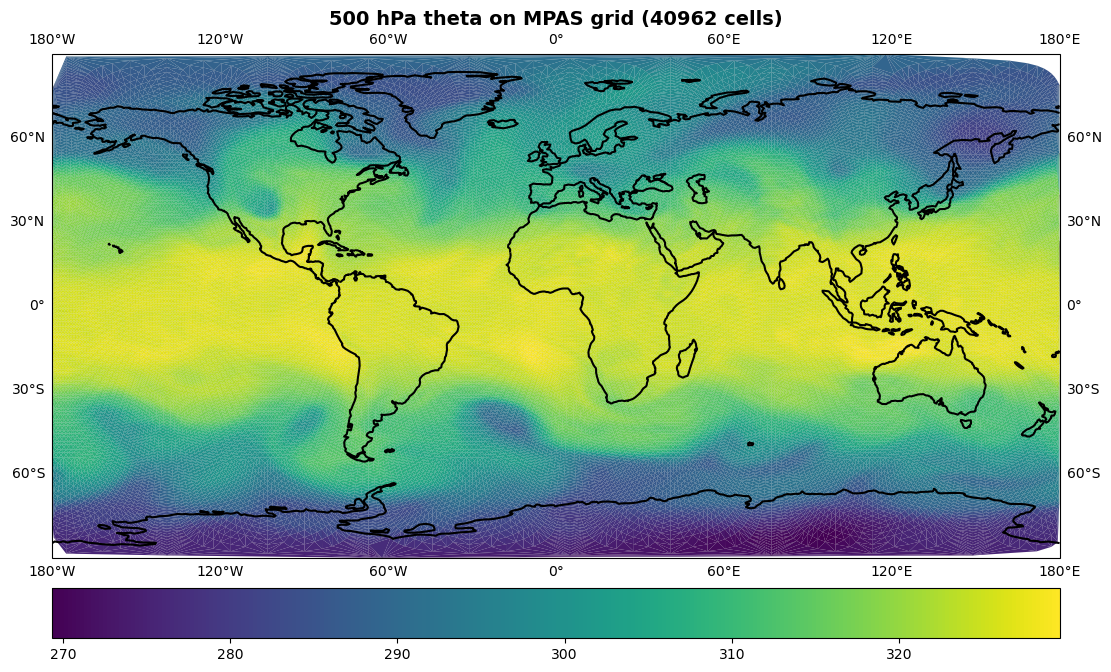

In [5]:
%%time

fig = plt.figure(figsize=(13, 13))
ax = plt.subplot(111, projection=ccrs.PlateCarree())

mm = ax.tripcolor(triang,
                  var_1d,
                  edgecolors='k',
                  lw=0.01,
                  alpha=1,
                  transform=ccrs.PlateCarree())

ax.set_global()
ax.coastlines(lw=1.5, resolution='110m')

gl = ax.gridlines(draw_labels=True)
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlines = gl.ylines = False

plt.colorbar(mm, orientation='horizontal', pad=0.03)
plt.title(str(int(p_1d[0]/100)) + " hPa theta on MPAS grid (" + str(len(ds_i.lonCell)) + " cells)",
          fontweight="bold",fontsize=14);

#### 2) Interpolating the data from the model's vertical grid to user-specified pressure levels

In [6]:
# user specified veritcal levels to interpolate to (1000-50 hPa, converted to Pa since pres is in Pa)
p_1d = np.atleast_1d(np.arange(1000, 50, -100)) * 100.0
n_p = len(p_1d)

# vertical interpolation
data_interp = vertical_interpolate_mpas(pres, theta, p_1d)
